In [1]:
from anemone.physics import *
from anemone import constants as c
from anemone.experiment import Receiver
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
sigma = 1/np.array([2, 80, 200, 80])
sigma = 10/np.array([0.1, 10, 10])
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.tensor([40, 40])

omega = torch.tensor([2000, 2010], dtype=torch.float64)*2*c.pi
lamda = torch.logspace(-2,4, 201, dtype=torch.float64)

In [3]:
x,y,z = torch.linspace(-50, 50, 200), torch.linspace(-50, 50, 76), torch.linspace(0, 160, 301)

In [4]:
rx = Receiver(x, y, z)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:28: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(

In [5]:
len(rx.z)

301

In [6]:
rx.z.shape

torch.Size([301])

In [7]:
from anemone.forwards import Forward
from anemone.physics import transverse_electric_field_coefficients as TEcoef
from anemone.transforms import Hankel

class vert_mag_dipole_FD(Forward):
    sofr = None
    Atot = None
    allr = None

    def __init__(self, source, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device

        self.allR = torch.sqrt(rx.X**2 + rx.Y**2).to(freqs.device)
        self.rvals = self.allR[..., 0].flatten()
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(self.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(self.device)
        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      

    def forward(self):
        omega = c.twopi*self.freqs[:,None]

        def Hz_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]

            if self.Atot is None:
                A,B,un = TEcoef(self.sigma, self.thick, omega, lmb, return_un=True)
                zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
                zsmp = self.receiver.z

                i_z = torch.searchsorted(zbnd, zsmp)-1
                zbnd[0] = 0.
                dz = zsmp-zbnd[i_z]

                Atot = torch.zeros((zsmp.shape+A[0].shape), dtype=torch.complex128)
                print('Atot shape is ', str(Atot.shape))
                for i in range(len(zbnd)):
                    z_slice = i_z==i
                    if z_slice.any():
                        cz = dz[z_slice][:, None, None]
                        u = un[i][None, ...]
                        cA,cB = A[i][None, ...], B[i][None, ...]
                        Atot[z_slice] = cA * torch.exp(-u*cz) + cB * torch.exp(u*cz)                
                if self.filterfunc is not None:
                    Atot *= self.filterfunc.omega_filter(omega)
                self.Atot = torch.nan_to_num(Atot)

            return torch.squeeze(self.Atot/c.fourpi * lmb**3 / un[0])
        
        def Hr_integrand(wave_length):
            """ Hr from horizontal electric dipole. """
            lmb = wave_length[None, :]
            return torch.squeeze(self.Atot/c.fourpi * lmb**2)            
        
        hklz = Hankel(Hz_integrand, 0, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        hklr = Hankel(Hr_integrand, 1, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)

        HzR = hklz(self.rvals).T.reshape(self.receiver.X.shape)
        HrR = hklr(self.rvals).T.reshape(self.receiver.X.shape)

        H = torch.zeros(HzR.shape+(3,), dtype=HzR.dtype).reshape(self.receiver.X.shape+(3,))
        
        H[..., 0] = HrR*self.receiver.X/self.allR
        H[..., 1] = HrR*self.receiver.Y/self.allR
        H[..., 2] = HzR
        return H

In [8]:
f = torch.tensor([2000.], dtype=torch.float64)

fwr = vert_mag_dipole_FD(rx, f)

TypeError: vert_mag_dipole_FD.__init__() missing 1 required positional argument: 'freqs'

In [10]:
H = fwr(sigma, thick)

NameError: name 'fwr' is not defined

In [11]:
H.shape

NameError: name 'H' is not defined

In [12]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 100, 2].numpy())), aspect='auto')

NameError: name 'H' is not defined

<Figure size 640x480 with 0 Axes>

In [13]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 0, 0].numpy())), aspect='auto')

NameError: name 'H' is not defined

<Figure size 640x480 with 0 Axes>

In [14]:
plt.figure()
plt.imshow(np.log10(np.abs(H[:, :, 0, 1].numpy())), aspect='auto')

NameError: name 'H' is not defined

<Figure size 640x480 with 0 Axes>

In [15]:
plt.figure()
pcm = plt.imshow(np.log10(np.abs(H[:, 35, :, 1].numpy())).T, aspect='auto')
plt.colorbar(pcm)

NameError: name 'H' is not defined

<Figure size 640x480 with 0 Axes>

In [16]:
from anemone.forwards import Forward
from anemone.physics import transverse_electric_field_coefficients as TEcoef, transverse_magnetic_field_coefficients as TMcoef
from anemone.transforms import Hankel

class vert_mag_dipole_FD(Forward):
    sofr = None
    Atot = None
    allr = None

    def __init__(self, L, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device

        self.L = L/2.

        self.allR = torch.sqrt(rx.X**2 + rx.Y**2).to(freqs.device)
        self.rvals = self.allR[..., 0].flatten()
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(self.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(self.device)
        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      

    def forward(self):
        omega = c.twopi*self.freqs[:,None]

        def Hz_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]

            if self.Atot is None:
                Fd,Fu,un = TEcoef(self.sigma, self.thick, omega, lmb, return_un=True)
                Ad,Au,un = TMcoef(self.sigma, self.thick, omega, lmb, return_un=True)
                zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
                zsmp = self.receiver.z

                i_z = torch.searchsorted(zbnd, zsmp)-1
                zbnd[0] = 0.
                dz = zsmp-zbnd[i_z]

                Atot = torch.zeros((zsmp.shape+A[0].shape), dtype=torch.complex128)
                print('Atot shape is ', str(Atot.shape))
                for i in range(len(zbnd)):
                    z_slice = i_z==i
                    if z_slice.any():
                        cz = dz[z_slice][:, None, None]
                        u = un[i][None, ...]
                        cA,cB = A[i][None, ...], B[i][None, ...]
                        Atot[z_slice] = cA * torch.exp(-u*cz) + cB * torch.exp(u*cz)                
                if self.filterfunc is not None:
                    Atot *= self.filterfunc.omega_filter(omega)
                self.Atot = torch.nan_to_num(Atot)

            return torch.squeeze(self.Atot/c.fourpi * lmb**3 / un[0])
        
        def Hr_integrand(wave_length):
            """ Hr from horizontal electric dipole. """
            lmb = wave_length[None, :]
            return torch.squeeze(self.Atot/c.fourpi * lmb**2)            
        
        hklz = Hankel(Hz_integrand, 0, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        hklr = Hankel(Hr_integrand, 1, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)

        HzR = hklz(self.rvals).T.reshape(self.receiver.X.shape)
        HrR = hklr(self.rvals).T.reshape(self.receiver.X.shape)

        H = torch.zeros(HzR.shape+(3,), dtype=HzR.dtype).reshape(self.receiver.X.shape+(3,))
        
        H[..., 0] = HrR*self.receiver.X/self.allR
        H[..., 1] = HrR*self.receiver.Y/self.allR
        H[..., 2] = HzR
        return H

In [11]:
from anemone.physics import refl_transverse_electric as rte, refl_transverse_magnetic as rtm

In [18]:
plt.figure()
pcm=plt.pcolor(*np.meshgrid(rx.x, rx.y), np.log10(np.abs(Hy.real.numpy()).T))
plt.colorbar(pcm)

NameError: name 'Hy' is not defined

<Figure size 640x480 with 0 Axes>

In [21]:
import torch
from anemone.experiment import getRz
S1 = lambda x: 1 - (9/4)*x**2 * ( 1 - 2./9*x*(1 + 5/2*x*(1 - 2/5 * x)))
S2 = lambda x: -1/2*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1-2/5*x))))

def lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x <= 1)
    x1p2  = (1 < x)*(x <= 2)
    
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1] = S1(x[x0p1])
    phi[x1p2] = S2(x[x1p2]-1)
    
    return phi


def s_of_rZ(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    s      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, None, :]
    dR     = dR[None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        x_ = x1[:,None] + (x2-x1)[:,None]*torch.linspace(0, 1, 101)[None, :]
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((cr-R)/dR)
        cs = y1 * phi * dx / cr
        s += cs.sum(axis=1, keepdims=False)

    return s


def s_of_rY(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    s      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, None, :]
    dR     = dR[None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        x_ = x1[:,None] + (x2-x1)[:,None]*torch.linspace(0, 1, 101)[None, :]
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((cr-R)/dR)
        cs = phi * dx
        s += cs.sum(axis=1, keepdims=False)

    return s


def s_of_r_ground(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    sx      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    sy      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, :]
    dR     = dR[None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        xm = (x1+x2)/2

        cr1 = torch.sqrt(y1**2 + x1**2)[:, None]
        phi1 = lamontagne((cr1-R)/dR)
        cr2 = torch.sqrt(y1**2 + x2**2)[:, None]
        phi2 = lamontagne((cr2-R)/dR)
        y1 = y1[:, None]
        x1 = x1[:, None]
        x2 = x2[:, None]
        xm = xm[:, None]
        
        sx += torch.nan_to_num((phi2-phi1)*y1 / R)
        sy += torch.nan_to_num(phi1*(x1-xm) / R)
        sy -= torch.nan_to_num(phi2*(x2-xm) / R)
    return sx,sy

In [33]:
from anemone.experiment import Loop, Receiver
from anemone import constants as c
from anemone.transforms import Hankel
from anemone.physics import refl_transverse_electric as rte, refl_transverse_magnetic as rtm
txX = Loop([-25, 25], [0, 0], [0, 0])
rx1 = Receiver(torch.linspace(-50, 50, 21), torch.linspace(-50, 50, 21))

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)


In [34]:
x1,x2 = -25, 25
X,Y = torch.meshgrid(rx1.x, rx1.y, indexing='ij')
R1 = torch.sqrt((X-x1)**2 + (Y)**2).flatten()
R2 = torch.sqrt((X-x2)**2 + (Y)**2).flatten()

sigma = 10./torch.tensor([40, 80, 200])[:, None, None]
thick = torch.tensor([40, 40])[:, None, None]


omega = torch.tensor([2000])[None, :, None]*2*c.pi

def Hgrnd_integrand(wave_length):
    """ Hz from horizontal electric dipole. """
    lmb = wave_length[None, None, :]

    cRTE = rte(sigma, thick, omega, lmb)
    cRTM = rtm(sigma, thick, omega, lmb)
    return torch.nan_to_num(cRTE+cRTM)

def Hydx_integrand(wave_length):
    """ Hz from horizontal electric dipole. """
    lmb = wave_length[None, None, :]
    cRTE = rte(sigma, thick, omega, lmb)

    return (1 - torch.nan_to_num(cRTE)) * lmb

def Hzdx_integrand(wave_length):
    """ Hz from horizontal electric dipole. """
    lmb = wave_length[None, None, :]
    cRTE = rte(sigma, thick, omega, lmb)

    return (1 + torch.nan_to_num(cRTE)) * lmb

hkl = Hankel(Hgrnd_integrand, 1, smp_per_decade=16)
r, HxR = hkl._range(torch.tensor([0.01]),torch.tensor([100]))

txX = Loop([-25, 25], [0, 0], [0, 0])
# rx1 = Receiver(rx.x, rx.y)

sX,sY = s_of_r_ground(txX, rx1, r)
sY2   = s_of_rY(txX, rx1, r)
sZ    = s_of_rZ(txX, rx1, r)

Hx = (sX@HxR.squeeze()).reshape(rx1.X.shape)
Hy = (sY@HxR.squeeze()).reshape(rx1.X.shape)

hkl = Hankel(Hydx_integrand, 0, smp_per_decade=16)
r, HyR = hkl._range(torch.tensor([0.01]),torch.tensor([100]))
Hy += (sY2@HyR.squeeze()).reshape(rx1.X.shape)

hkl = Hankel(Hzdx_integrand, 1, smp_per_decade=16)
r, HzR = hkl._range(torch.tensor([0.01]),torch.tensor([100]))
Hz = (sZ@HzR.squeeze()).reshape(rx1.X.shape)

C:\Users\au646858\AppData\Local\Temp\ipykernel_23664\3932227619.py:98: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_23664\3932227619.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_23664\3932227619.py:22: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


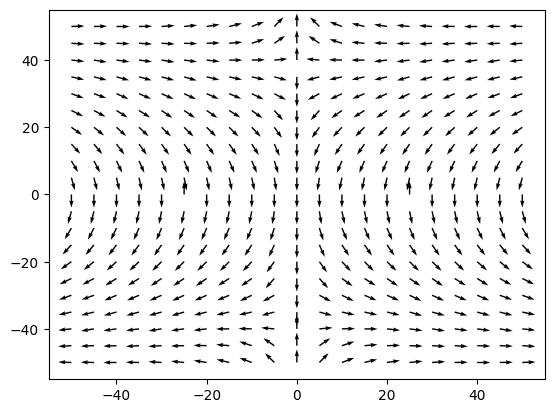

In [35]:
nHx,nHy = Hx.real/(Hx.real**2+Hy.real**2)**0.5, Hy.real/(Hx.real**2+Hy.real**2)**0.5

plt.figure()
plt.quiver(rx1.X, rx1.Y, nHx, nHy)

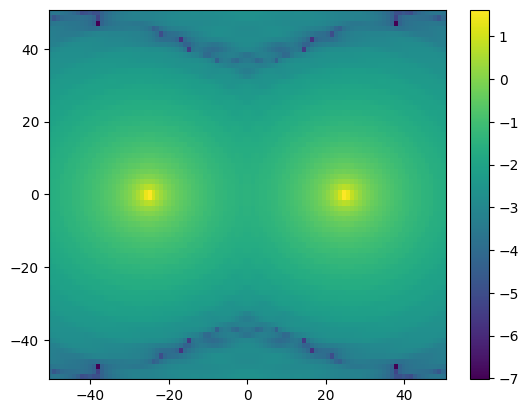

In [29]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
pcm=plt.pcolor(*np.meshgrid(rx1.x, rx1.y), np.log10(np.abs(Hy.numpy().real.T)))
plt.colorbar(pcm)

In [4]:
fig,axs = plt.subplots(3,1, figsize=(5,10))
pcm=axs[0].pcolor(rx1.X, rx1.Y, Hx0.real)
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].pcolor(rx1.X, rx1.Y, Hx.real)
plt.colorbar(pcm, ax=axs[1])
pcm=axs[2].pcolor(rx1.X, rx1.Y, np.abs((Hx0+Hx)/Hx0).numpy())
plt.colorbar(pcm, ax=axs[2])

NameError: name 'plt' is not defined

In [5]:
fig,axs = plt.subplots(3,1, figsize=(5,10))
pcm=axs[0].pcolor(rx1.X, rx1.Y, Hy0.real.numpy())
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].pcolor(rx1.X, rx1.Y, Hy.real.numpy())
plt.colorbar(pcm, ax=axs[1])
pcm=axs[2].pcolor(rx1.X, rx1.Y, np.abs((Hy0+Hy)/Hy0.numpy()))
plt.colorbar(pcm, ax=axs[2])

NameError: name 'plt' is not defined